In [1]:
import pandas as pd

df = pd.read_parquet("data/yellow_tripdata_2025-01.parquet")
print(df.shape)
print(df.columns.tolist())
print()
print(df.head(3).T)

(3475226, 20)
['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee']

                                         0                    1  \
VendorID                                 1                    1   
tpep_pickup_datetime   2025-01-01 00:18:38  2025-01-01 00:32:40   
tpep_dropoff_datetime  2025-01-01 00:26:59  2025-01-01 00:35:13   
passenger_count                        1.0                  1.0   
trip_distance                          1.6                  0.5   
RatecodeID                             1.0                  1.0   
store_and_fwd_flag                       N                    N   
PULocationID                           229                  236   
DOLocationID                     

In [2]:
minutes = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
pickup = df["tpep_pickup_datetime"]

checks = {
    "Distance is zero or negative": df["trip_distance"] <= 0,
    "Distance over 100 miles": df["trip_distance"] > 100,
    "Fare is zero or negative": df["fare_amount"] <= 0,
    "Total is zero or negative": df["total_amount"] <= 0,
    "Trip ends before it starts": minutes <= 0,
    "Trip longer than 24 hours": minutes > 24 * 60,
    "Pickup not in January 2025": (pickup < "2025-01-01") | (pickup >= "2025-02-01"),
    "Passenger count missing": df["passenger_count"].isna(),
    "Passenger count is 0": df["passenger_count"] == 0,
}

for name, bad in checks.items():
    print(name, "|", bad.sum(), "|", round(bad.mean() * 100, 2), "%")

print()
print("Trips with at least one problem:", pd.DataFrame(checks).any(axis=1).sum())

Distance is zero or negative | 90893 | 2.62 %
Distance over 100 miles | 162 | 0.0 %
Fare is zero or negative | 145516 | 4.19 %
Total is zero or negative | 63596 | 1.83 %
Trip ends before it starts | 2051 | 0.06 %
Trip longer than 24 hours | 20 | 0.0 %
Pickup not in January 2025 | 22 | 0.0 %
Passenger count missing | 540149 | 15.54 %
Passenger count is 0 | 24656 | 0.71 %

Trips with at least one problem: 659691


In [3]:
bad_fare = df[df["fare_amount"] <= 0]

print("Payment types among zero/negative fares:")
print(bad_fare["payment_type"].value_counts())
print()
print("Payment types among all trips:")
print(df["payment_type"].value_counts())
print()
print("Zero/negative fares with a positive total:", (bad_fare["total_amount"] > 0).sum())

Payment types among zero/negative fares:
payment_type
0    84861
4    37694
2    14579
3     8280
1      101
5        1
Name: count, dtype: int64

Payment types among all trips:
payment_type
1    2444393
0     540149
2     390429
4      76481
3      23773
5          1
Name: count, dtype: int64

Zero/negative fares with a positive total: 81952


In [4]:
missing = df["passenger_count"].isna()
flex = df["payment_type"] == 0

print("Missing passenger count AND Flex Fare:", (missing & flex).sum())
print("Missing passenger count but NOT Flex Fare:", (missing & ~flex).sum())
print()
print("Credit card trips with a zero or negative fare (first 5):")
print(df[(df["payment_type"] == 1) & (df["fare_amount"] <= 0)][["trip_distance", "fare_amount", "total_amount"]].head(5))

Missing passenger count AND Flex Fare: 540149
Missing passenger count but NOT Flex Fare: 0

Credit card trips with a zero or negative fare (first 5):
        trip_distance  fare_amount  total_amount
31462           19.40          0.0         99.69
81929            0.00          0.0          0.00
86042            5.80          0.0          0.00
150056           0.00          0.0          0.00
160324          10.65        -42.2        -45.45


In [5]:
minutes = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
pickup = df["tpep_pickup_datetime"]

rules = [
    ("pickup outside January 2025", (pickup < "2025-01-01") | (pickup >= "2025-02-01")),
    ("trip ends before or when it starts", minutes <= 0),
    ("trip longer than 24 hours", minutes > 24 * 60),
    ("distance over 100 miles", df["trip_distance"] > 100),
    ("distance zero or negative", df["trip_distance"] <= 0),
    ("fare zero or negative", df["fare_amount"] <= 0),
    ("total zero or negative", df["total_amount"] <= 0),
]

reason = pd.Series("", index=df.index)
for name, bad in rules:
    reason = reason.mask((reason == "") & bad, name)

print(reason[reason != ""].value_counts())
print()
kept = (reason == "").sum()
rejected = (reason != "").sum()
print("Kept:", kept)
print("Rejected:", rejected)
print("Kept + rejected =", kept + rejected, "| original rows =", len(df))
print("Match:", kept + rejected == len(df))

fare zero or negative                 130434
distance zero or negative              90196
trip ends before or when it starts      2051
distance over 100 miles                  161
total zero or negative                    23
pickup outside January 2025               22
trip longer than 24 hours                 20
Name: count, dtype: int64

Kept: 3252319
Rejected: 222907
Kept + rejected = 3475226 | original rows = 3475226
Match: True


In [6]:
%%writefile clean_data.py
"""Clean one month of NYC yellow taxi trips.

Rejected trips are saved with the reason, so nothing disappears silently.
"""
import argparse
import pandas as pd


def find_rejection_reasons(df, month):
    """Return a Series with the first broken rule for each trip ('' = keep)."""
    start = pd.Timestamp(month + "-01")
    end = start + pd.offsets.MonthBegin(1)
    pickup = df["tpep_pickup_datetime"]
    minutes = (df["tpep_dropoff_datetime"] - pickup).dt.total_seconds() / 60

    rules = [
        ("pickup outside the month", (pickup < start) | (pickup >= end)),
        ("trip ends before or when it starts", minutes <= 0),
        ("trip longer than 24 hours", minutes > 24 * 60),
        ("distance over 100 miles", df["trip_distance"] > 100),
        ("distance zero or negative", df["trip_distance"] <= 0),
        ("fare zero or negative", df["fare_amount"] <= 0),
        ("total zero or negative", df["total_amount"] <= 0),
    ]

    reason = pd.Series("", index=df.index)
    for name, bad in rules:
        reason = reason.mask((reason == "") & bad, name)
    return reason


def clean(df, month):
    """Split trips into kept and rejected, and check the row counts add up."""
    reason = find_rejection_reasons(df, month)

    kept = df[reason == ""].copy()
    kept["missing_passenger_count"] = kept["passenger_count"].isna()
    kept["passenger_count_zero"] = kept["passenger_count"] == 0

    rejected = df[reason != ""].copy()
    rejected["reject_reason"] = reason[reason != ""]

    if len(kept) + len(rejected) != len(df):
        raise ValueError("Row counts do not add up")
    return kept, rejected


def main():
    parser = argparse.ArgumentParser(description="Clean one month of taxi trips")
    parser.add_argument("--input", default="data/yellow_tripdata_2025-01.parquet")
    parser.add_argument("--month", default="2025-01")
    args = parser.parse_args()

    df = pd.read_parquet(args.input)
    kept, rejected = clean(df, args.month)

    kept.to_parquet(f"data/clean_{args.month}.parquet", index=False)
    rejected.to_parquet(f"data/rejected_{args.month}.parquet", index=False)

    print("Trips in:", len(df))
    print("Kept:", len(kept))
    print("Rejected:", len(rejected), f"({len(rejected) / len(df) * 100:.1f}%)")
    print()
    print(rejected["reject_reason"].value_counts().to_string())
    print()
    print("Kept but flagged, missing passenger count:", int(kept["missing_passenger_count"].sum()))
    print("Kept but flagged, passenger count zero:", int(kept["passenger_count_zero"].sum()))
    print("Row counts add up:", len(kept) + len(rejected) == len(df))


if __name__ == "__main__":
    main()

Writing clean_data.py


In [7]:
%%writefile test_clean_data.py
import pandas as pd
import pytest
from clean_data import clean

MONTH = "2025-01"


def make_trip(**changes):
    """One good trip, with any column changed as asked."""
    trip = {
        "tpep_pickup_datetime": pd.Timestamp("2025-01-10 08:00"),
        "tpep_dropoff_datetime": pd.Timestamp("2025-01-10 08:20"),
        "passenger_count": 1.0,
        "trip_distance": 3.0,
        "fare_amount": 15.0,
        "total_amount": 20.0,
    }
    trip.update(changes)
    return trip


def run(*trips):
    return clean(pd.DataFrame(list(trips)), MONTH)


def test_good_trip_is_kept():
    kept, rejected = run(make_trip())
    assert len(kept) == 1
    assert len(rejected) == 0


@pytest.mark.parametrize("changes, expected_reason", [
    ({"tpep_pickup_datetime": pd.Timestamp("2025-02-05 08:00"),
      "tpep_dropoff_datetime": pd.Timestamp("2025-02-05 08:20")}, "pickup outside the month"),
    ({"tpep_dropoff_datetime": pd.Timestamp("2025-01-10 07:50")}, "trip ends before or when it starts"),
    ({"tpep_dropoff_datetime": pd.Timestamp("2025-01-11 09:00")}, "trip longer than 24 hours"),
    ({"trip_distance": 150.0}, "distance over 100 miles"),
    ({"trip_distance": 0.0}, "distance zero or negative"),
    ({"fare_amount": -5.0}, "fare zero or negative"),
    ({"total_amount": 0.0}, "total zero or negative"),
])
def test_bad_trip_is_rejected_with_reason(changes, expected_reason):
    kept, rejected = run(make_trip(**changes))
    assert len(kept) == 0
    assert rejected["reject_reason"].iloc[0] == expected_reason


def test_missing_passenger_count_is_kept_and_flagged():
    kept, rejected = run(make_trip(passenger_count=float("nan")))
    assert len(kept) == 1
    assert bool(kept["missing_passenger_count"].iloc[0]) is True


def test_zero_passenger_count_is_kept_and_flagged():
    kept, rejected = run(make_trip(passenger_count=0.0))
    assert len(kept) == 1
    assert bool(kept["passenger_count_zero"].iloc[0]) is True


def test_row_counts_add_up():
    trips = [make_trip(), make_trip(trip_distance=0.0), make_trip(fare_amount=-1.0), make_trip()]
    kept, rejected = run(*trips)
    assert len(kept) + len(rejected) == len(trips)


def test_trip_breaking_several_rules_is_counted_once():
    kept, rejected = run(make_trip(trip_distance=0.0, fare_amount=0.0, total_amount=0.0))
    assert len(rejected) == 1
    assert rejected["reject_reason"].iloc[0] == "distance zero or negative"

Writing test_clean_data.py


       trips  avg_fare  avg_distance
hour                                
0      86524     18.73          3.67
1      59505     17.16          3.23
2      40203     16.33          3.08
3      25557     17.15          3.43
4      17931     22.14          4.80
5      20509     25.42          5.78
6      46596     21.27          4.55
7      96732     19.09          3.58
8     133760     17.73          2.98
9     137163     17.35          2.90
10    142957     17.47          2.95
11    154325     17.29          2.86
12    168424     22.68          2.94
13    178462     18.07          3.06
14    193867     18.66          3.19
15    204413     18.75          3.20
16    203020     18.77          3.24
17    229253     17.44          2.88
18    236452     16.51          2.70
19    200556     17.07          2.98
20    184545     17.58          3.25
21    194131     17.71          3.28
22    170457     18.27          3.41
23    126977     19.04          3.74


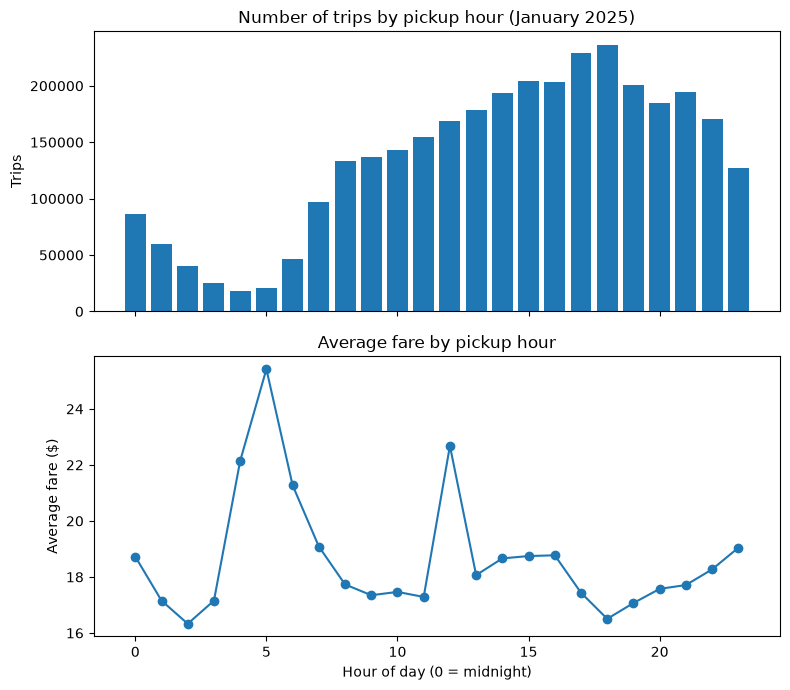

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

clean = pd.read_parquet("data/clean_2025-01.parquet")
clean["hour"] = clean["tpep_pickup_datetime"].dt.hour

by_hour = clean.groupby("hour").agg(
    trips=("fare_amount", "size"),
    avg_fare=("fare_amount", "mean"),
    avg_distance=("trip_distance", "mean"),
)
print(by_hour.round(2))

fig, (top, bottom) = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
top.bar(by_hour.index, by_hour["trips"])
top.set_title("Number of trips by pickup hour (January 2025)")
top.set_ylabel("Trips")
bottom.plot(by_hour.index, by_hour["avg_fare"], marker="o")
bottom.set_title("Average fare by pickup hour")
bottom.set_ylabel("Average fare ($)")
bottom.set_xlabel("Hour of day (0 = midnight)")
plt.tight_layout()
plt.savefig("fares_by_hour.png", dpi=150)
plt.show()

In [9]:
noon = clean[clean["hour"] == 12]
print(noon["fare_amount"].describe().round(2))
print()
print(noon.nlargest(5, "fare_amount")[["tpep_pickup_datetime", "trip_distance", "fare_amount", "total_amount"]])
print()
print("Median fare by hour:")
print(clean.groupby("hour")["fare_amount"].median().round(2).to_string())

count    168424.00
mean         22.68
std        2103.78
min           0.01
25%           8.60
50%          12.65
75%          19.11
max      863372.12
Name: fare_amount, dtype: float64

        tpep_pickup_datetime  trip_distance  fare_amount  total_amount
1721239  2025-01-20 12:07:18           1.60    863372.12     863380.37
687560   2025-01-09 12:56:34          81.14       579.80        616.36
2309947  2025-01-26 12:35:30          98.50       500.00        517.81
983664   2025-01-12 12:55:55          76.44       411.80        461.05
1799571  2025-01-21 12:25:09          58.42       385.90        409.15

Median fare by hour:
hour
0     13.50
1     12.80
2     12.62
3     12.80
4     14.90
5     15.01
6     12.80
7     12.80
8     12.80
9     12.80
10    12.80
11    12.80
12    12.65
13    12.80
14    12.80
15    12.80
16    12.80
17    12.80
18    12.10
19    12.10
20    12.80
21    12.80
22    13.50
23    13.50


In [10]:
for limit in [200, 500, 1000, 10000]:
    print("Fare over $" + str(limit), "|", (clean["fare_amount"] > limit).sum())

print()
print("Largest fares, with distance:")
print(clean.nlargest(12, "fare_amount")[["trip_distance", "fare_amount"]].to_string())

Fare over $200 | 816
Fare over $500 | 22
Fare over $1000 | 1
Fare over $10000 | 1

Largest fares, with distance:
         trip_distance  fare_amount
1721239           1.60    863372.12
541020            0.10       900.00
1120467           0.35       700.00
867492           78.94       634.40
655481           95.59       607.10
657678           36.73       600.00
1910029          83.02       596.60
556732           87.92       595.20
687560           81.14       579.80
2597374           1.07       577.70
1467838          91.70       562.30
2224441          91.93       562.30


In [11]:
for fare_limit, miles_limit in [(100, 10), (100, 5), (200, 10), (200, 20)]:
    hit = clean[(clean["fare_amount"] > fare_limit) & (clean["trip_distance"] < miles_limit)]
    print("Fare over $" + str(fare_limit), "and under", miles_limit, "miles |", len(hit))

print()
suspect = clean[(clean["fare_amount"] > 100) & (clean["trip_distance"] < 10)]
print(suspect.nlargest(12, "fare_amount")[["trip_distance", "fare_amount", "total_amount"]].to_string())

Fare over $100 and under 10 miles | 257
Fare over $100 and under 5 miles | 215
Fare over $200 and under 10 miles | 38
Fare over $200 and under 20 miles | 53

         trip_distance  fare_amount  total_amount
1721239           1.60    863372.12     863380.37
541020            0.10       900.00        901.00
1120467           0.35       700.00        704.25
2597374           1.07       577.70        581.70
756032            0.01       450.00        451.00
751630            0.46       400.00        403.50
851414            0.01       400.00        404.25
2236777           6.31       400.00        414.25
735552            0.46       350.00        456.30
1620470           0.03       350.00        369.25
1779018           0.27       347.00        358.00
355500            0.06       308.00        309.00


In [12]:
text = open("clean_data.py").read()

a1 = '        ("fare zero or negative", df["fare_amount"] <= 0),\n'
a2 = '    kept["passenger_count_zero"] = kept["passenger_count"] == 0\n'
a3 = '    print("Kept but flagged, passenger count zero:", int(kept["passenger_count_zero"].sum()))\n'
for anchor in (a1, a2, a3):
    assert text.count(anchor) == 1, "Could not find: " + anchor

text = text.replace(a1,
    '        ("fare over $200 on a trip under 10 miles", (df["fare_amount"] > 200) & (df["trip_distance"] < 10)),\n' + a1)
text = text.replace(a2,
    a2 + '    kept["fare_high_for_distance"] = (kept["fare_amount"] > 100) & (kept["trip_distance"] < 10)\n')
text = text.replace(a3,
    a3 + '    print("Kept but flagged, fare over $100 on a trip under 10 miles:", int(kept["fare_high_for_distance"].sum()))\n')
open("clean_data.py", "w").write(text)

new_tests = '''

def test_very_high_fare_on_short_trip_is_rejected():
    kept, rejected = run(make_trip(trip_distance=0.1, fare_amount=900.0, total_amount=901.0))
    assert len(kept) == 0
    assert rejected["reject_reason"].iloc[0] == "fare over $200 on a trip under 10 miles"


def test_high_fare_on_long_trip_is_kept():
    kept, rejected = run(make_trip(trip_distance=90.0, fare_amount=600.0, total_amount=620.0))
    assert len(kept) == 1
    assert bool(kept["fare_high_for_distance"].iloc[0]) is False


def test_moderately_high_fare_on_short_trip_is_kept_and_flagged():
    kept, rejected = run(make_trip(trip_distance=3.0, fare_amount=150.0, total_amount=160.0))
    assert len(kept) == 1
    assert bool(kept["fare_high_for_distance"].iloc[0]) is True
'''
with open("test_clean_data.py", "a") as f:
    f.write(new_tests)
print("Both files updated")

Both files updated


       trips  median_fare  median_distance
hour                                      
0      86523        13.50             2.10
1      59505        12.80             2.05
2      40202        12.62             2.04
3      25557        12.80             2.17
4      17931        14.90             2.80
5      20507        15.00             2.82
6      46596        12.80             2.22
7      96732        12.80             1.90
8     133759        12.80             1.69
9     137163        12.80             1.60
10    142955        12.80             1.58
11    154325        12.80             1.53
12    168423        12.65             1.52
13    178459        12.80             1.57
14    193867        12.80             1.60
15    204412        12.80             1.60
16    203019        12.80             1.60
17    229250        12.80             1.58
18    236449        12.10             1.56
19    200551        12.10             1.63
20    184542        12.80             1.81
21    19413

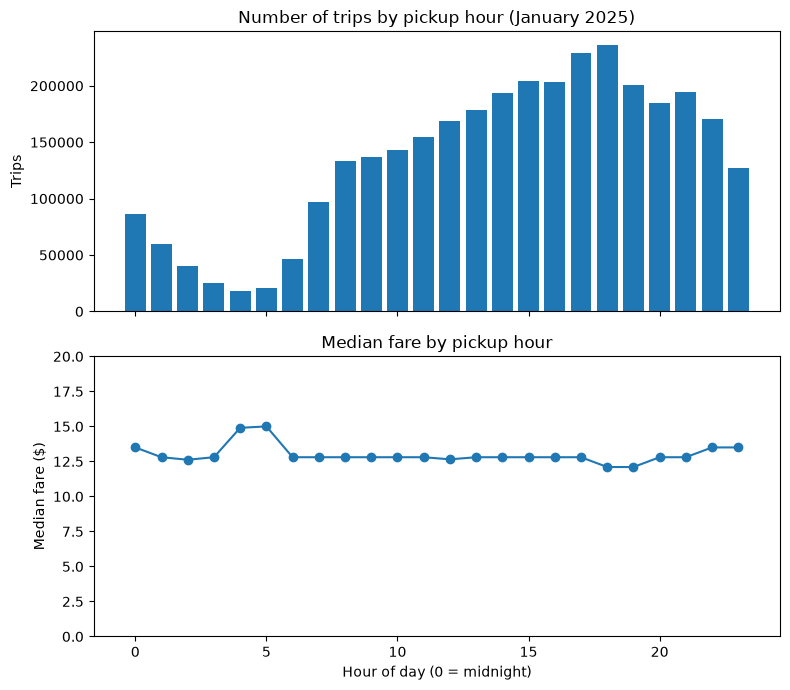

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

clean = pd.read_parquet("data/clean_2025-01.parquet")
clean["hour"] = clean["tpep_pickup_datetime"].dt.hour

by_hour = clean.groupby("hour").agg(
    trips=("fare_amount", "size"),
    median_fare=("fare_amount", "median"),
    median_distance=("trip_distance", "median"),
)
print(by_hour.round(2))
print()
print("Largest fare now:", clean["fare_amount"].max())

fig, (top, bottom) = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
top.bar(by_hour.index, by_hour["trips"])
top.set_title("Number of trips by pickup hour (January 2025)")
top.set_ylabel("Trips")
bottom.plot(by_hour.index, by_hour["median_fare"], marker="o")
bottom.set_title("Median fare by pickup hour")
bottom.set_ylabel("Median fare ($)")
bottom.set_xlabel("Hour of day (0 = midnight)")
bottom.set_ylim(0, 20)
plt.tight_layout()
plt.savefig("fares_by_hour.png", dpi=150)
plt.show()


In [14]:
readme = r"""# NYC Taxi Trip Cleaning Pipeline

A small, tested Python pipeline that cleans one month of NYC yellow taxi trips (3.5 million rows) and records the reason for every trip it removes.

## Why I built this

Raw trip data has errors. In my first chart, a single trip with a fare of $863,372 for 1.6 miles pulled the average fare at noon up by about $5. Putting the cleaning rules in a script with tests, instead of a one-off notebook, means the same rules run the same way every time, and the work can be checked.

## What it does

- Reads one month of trips from a Parquet file.
- Applies the rules below and saves two files: `clean_<month>.parquet` and `rejected_<month>.parquet`.
- Rejected trips are never deleted silently. Each one is saved with the reason it was rejected.
- A trip that breaks several rules is counted once, under the first rule it breaks.
- The script stops with an error if kept + rejected does not equal the number of trips read.

## Results for January 2025

Trips in: 3,475,226. Kept: 3,252,281. Rejected: 222,945 (6.4%).

| Rejection reason | Trips |
|---|---|
| fare zero or negative | 130,434 |
| distance zero or negative | 90,196 |
| trip ends before or when it starts | 2,051 |
| distance over 100 miles | 161 |
| fare over $200 on a trip under 10 miles | 38 |
| total zero or negative | 23 |
| pickup outside the month | 22 |
| trip longer than 24 hours | 20 |

Kept but flagged, not removed:

- 413,153 trips with a missing passenger count. In the raw data, every missing passenger count was on a payment type 0 trip (listed as Flex Fare in the TLC data dictionary), so a missing count is not an error and removing these would have thrown away good trips.
- 23,631 trips with a passenger count of 0.
- 219 trips with a fare over $100 on a trip under 10 miles. These may be real (long waits, heavy traffic, tolls), so they are flagged for review instead of removed.

## Finding: the typical fare barely changes by hour

![Trips and median fare by pickup hour](fares_by_hour.png)

- The busiest hour is 6 pm (about 236,000 trips) and the quietest is 4 am (about 18,000 trips).
- The median fare is about $12 to $15 at every hour: lowest in the evening rush and highest at 4 to 5 am.
- Average fares looked very different, because a few extreme trips pull an average up. I used the median for that reason.
- This shows how fares differ by hour, not why. I did not test whether distance, traffic or airport trips explain the early-morning difference.

## How to run it

1. Download a month of yellow taxi trips (Parquet) from the NYC TLC Trip Record Data page and put the file in a folder named `data`. The data files are not included in this repository because of their size.
2. Install the libraries and run the pipeline:

        pip install -r requirements.txt
        python clean_data.py --input data/yellow_tripdata_2025-01.parquet --month 2025-01
        python -m pytest -v

## Tests

There are 15 tests in `test_clean_data.py`. Each uses a few made-up trips with a known right answer. They check that every rule rejects the right trips with the right reason, that missing and zero passenger counts are kept and flagged, that long trips with high fares are kept, and that the row counts always add up.

## Limitations

- Only one month (January 2025) was cleaned and analysed.
- The cutoffs ($200, $100 and 10 miles) were chosen by looking at this month's data. They have not been checked on other months.
- Zero and negative fares can be legitimate (disputes, refunds, no-charge trips). The pipeline rejects them because they cannot be used for a fare analysis, not because they are always errors.
- Fares exclude tips and extras.
- The hourly analysis does not separate weekdays from weekends.

## Files

- `clean_data.py`: the pipeline.
- `test_clean_data.py`: the tests.
- `01_explore.ipynb`: the exploration that led to the rules.
- `fares_by_hour.png`: the chart above.

Data: NYC Taxi and Limousine Commission (TLC) Trip Record Data.
"""
open("README.md", "w", encoding="utf-8").write(readme)
open("requirements.txt", "w").write("pandas\npyarrow\nmatplotlib\npytest\n")
print("README.md and requirements.txt created")

README.md and requirements.txt created
